# Risk class classification: evaluation

Load the models saved by `training.ipynb` and score them on the **same held-out test set**:
summary metrics, per-class statistics and confusion matrices (counts and row-normalised).

Run `training.ipynb` first.

In [1]:
import json

import numpy as np
import pandas as pd

from pathlib import Path
import time

from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

import joblib
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path.cwd().parent.parent
DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "prediction" / "ml" / "models"

CRITICAL_CLASS = 3   # highest risk class, tracked separately as "critical_recall"
SORT_METRIC = "accuracy"

MODEL_LABELS = {
    "knn": "KNN",
    "lr": "Logistic Regression",
    "rf": "Random Forest",
    "svm": "SVM (RBF)",
    "nb": "Naive Bayes",
    "hgb": "Hist. Gradient Boosting",
}

## Load test set and models

In [3]:
df = pd.read_csv(DATA_DIR / "patient_preprocessed.csv")
df = df.drop(columns=["PATIENT"])

with open(MODELS_DIR / "split.json") as f:
    split = json.load(f)

test = df.loc[split["test_index"]]
X_test = test.drop(columns=["risk_score", "risk_class"])
y_test = test["risk_class"]
classes = sorted(y_test.unique())

print(X_test.shape)
y_test.value_counts(normalize=True).sort_index().round(3)

(20638, 55)


risk_class
0    0.842
1    0.099
2    0.043
3    0.016
Name: proportion, dtype: float64

In [4]:
models = {
    path.stem.removesuffix("_model"): joblib.load(path)
    for path in sorted(MODELS_DIR.glob("*_model.joblib"))
}

with open(MODELS_DIR / "best_params.json") as f:
    best_params = json.load(f)

print("loaded:", ", ".join(models))
pd.Series({name: str(p) for name, p in best_params.items()}, name="best params").to_frame()

loaded: hgb, knn, lr, nb, rf, svm


,best params
knn,"{'kneighborsclassifier__n_neighbors': 17, 'kne..."
lr,"{'logisticregression__C': 0.1, 'logisticregres..."
rf,"{'n_estimators': 100, 'min_samples_split': 2, ..."
svm,"{'svc__gamma': 0.01, 'svc__class_weight': None..."
nb,{'var_smoothing': 1.0}
hgb,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31,..."


## Predictions and metrics

In [5]:
predictions, results = {}, {}

for name, model in models.items():
    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    predict_time = time.perf_counter() - t0

    predictions[name] = y_pred
    results[name] = {
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "recall_macro": recall_score(y_test, y_pred, average="macro"),
        "critical_recall": recall_score(y_test, y_pred, labels=[CRITICAL_CLASS], average="macro", zero_division=0),
        "predict_time_s": predict_time,
    }

results_df = pd.DataFrame(results).T.sort_values(SORT_METRIC, ascending=False)
results_df.round(4)

,accuracy,f1_macro,recall_macro,critical_recall,predict_time_s
hgb,0.8565,0.4789,0.4359,0.5118,0.3153
rf,0.8546,0.4408,0.4034,0.4763,0.0852
knn,0.8542,0.4693,0.4190,0.4408,1.4961
svm,0.8525,0.4377,0.4016,0.4734,13.9601
lr,0.8483,0.3944,0.3598,0.3314,0.0131
nb,0.8423,0.2286,0.2500,0.0000,0.0448


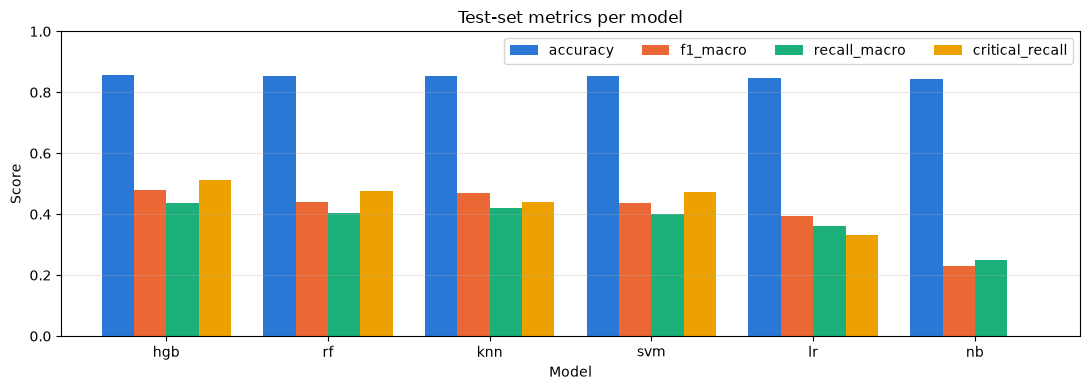

In [6]:
metric_cols = ["accuracy", "f1_macro", "recall_macro", "critical_recall"]
metric_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

ax = results_df[metric_cols].plot.bar(figsize=(11, 4), rot=0, color=metric_colors, width=0.8)
ax.set_ylim(0, 1)
ax.set_title("Test-set metrics per model")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right", ncols=4)

plt.tight_layout()
plt.show()

## Per-class statistics

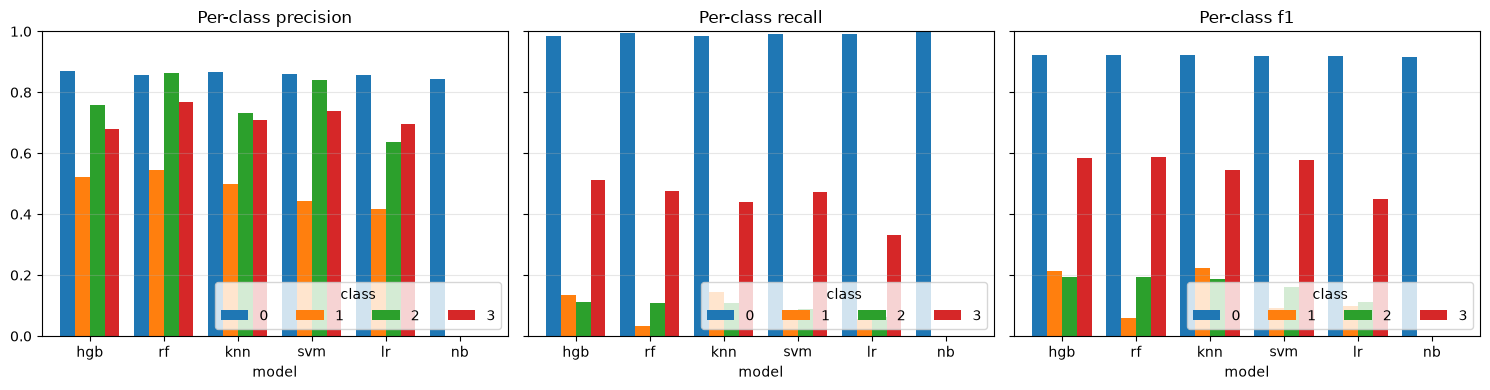

===== Hist. Gradient Boosting =====
              precision    recall  f1-score   support

           0      0.868     0.985     0.923     17384
           1      0.522     0.135     0.215      2037
           2      0.760     0.111     0.194       879
           3      0.678     0.512     0.583       338

    accuracy                          0.857     20638
   macro avg      0.707     0.436     0.479     20638
weighted avg      0.826     0.857     0.817     20638

===== Random Forest =====
              precision    recall  f1-score   support

           0      0.857     0.996     0.922     17384
           1      0.546     0.032     0.060      2037
           2      0.865     0.109     0.194       879
           3      0.767     0.476     0.588       338

    accuracy                          0.855     20638
   macro avg      0.759     0.403     0.441     20638
weighted avg      0.825     0.855     0.800     20638

===== KNN =====
              precision    recall  f1-score   suppor

In [7]:
rows = []
for name, y_pred in predictions.items():
    precision = precision_score(y_test, y_pred, labels=classes, average=None, zero_division=0)
    recall = recall_score(y_test, y_pred, labels=classes, average=None, zero_division=0)
    f1 = f1_score(y_test, y_pred, labels=classes, average=None, zero_division=0)
    for c, p, r, f in zip(classes, precision, recall, f1):
        rows.append({"model": name, "class": c, "precision": p, "recall": r, "f1": f})

per_class = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    per_class.pivot(index="model", columns="class", values=metric).loc[results_df.index].plot.bar(ax=ax, rot=0, width=0.8)
    ax.set_title(f"Per-class {metric}")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="class", ncols=len(classes), loc="lower right")
plt.tight_layout()
plt.show()

for name in results_df.index:
    print(f"===== {MODEL_LABELS.get(name, name)} =====")
    print(classification_report(y_test, predictions[name], digits=3, zero_division=0))

## Confusion matrices

Row-normalised (each row sums to 1, so the diagonal is the per-class recall) with the raw counts underneath.

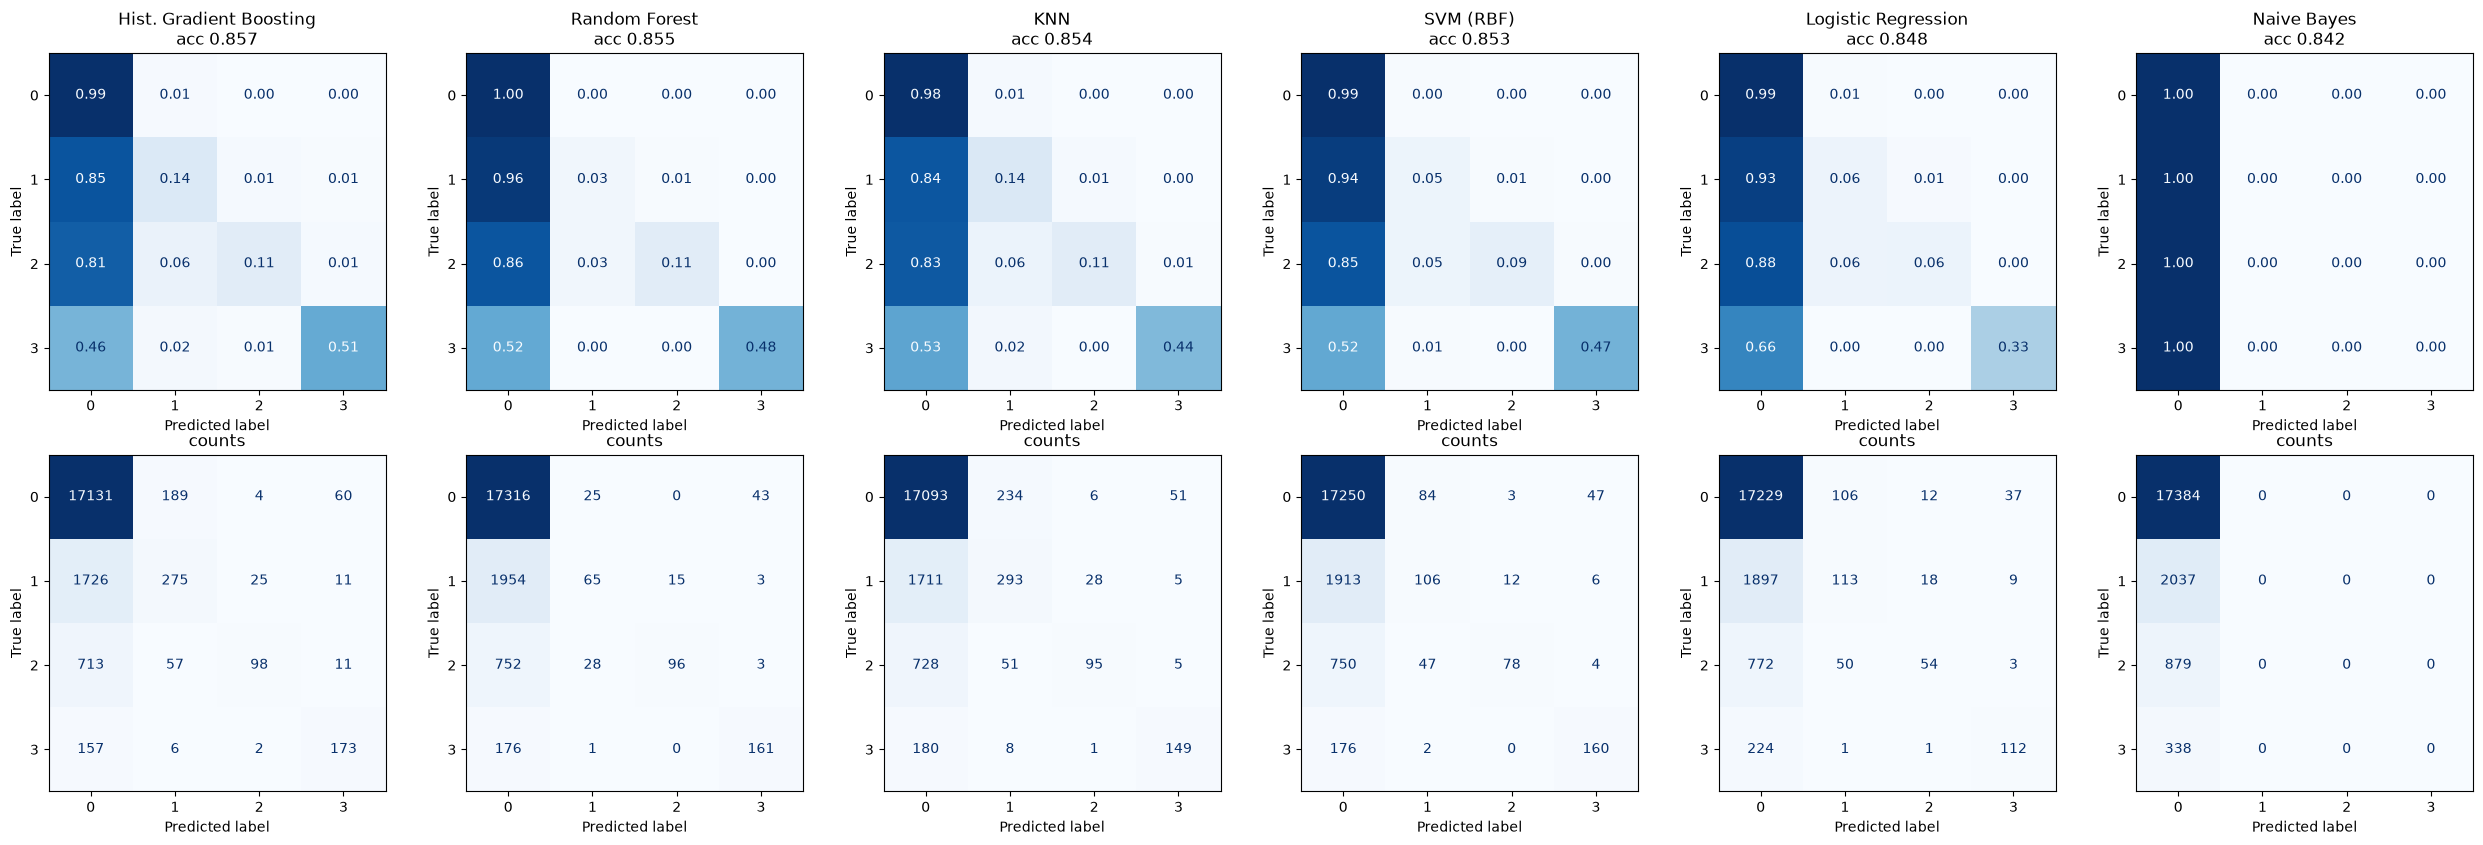

In [8]:
n = len(models)
fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 8.4), squeeze=False)

for col, name in enumerate(results_df.index):
    y_pred = predictions[name]
    title = f"{MODEL_LABELS.get(name, name)}\nacc {results_df.loc[name, 'accuracy']:.3f}"

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=classes, normalize="true", cmap="Blues",
        values_format=".2f", ax=axes[0, col], colorbar=False,
    )
    axes[0, col].set_title(title)

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=classes, cmap="Blues",
        values_format="d", ax=axes[1, col], colorbar=False,
    )
    axes[1, col].set_title("counts")

plt.tight_layout()
plt.show()

## Best model

Best model by accuracy: Hist. Gradient Boosting
params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 400, 'learning_rate': 0.03, 'l2_regularization': 0.1, 'class_weight': None}

              precision    recall  f1-score   support

           0      0.868     0.985     0.923     17384
           1      0.522     0.135     0.215      2037
           2      0.760     0.111     0.194       879
           3      0.678     0.512     0.583       338

    accuracy                          0.857     20638
   macro avg      0.707     0.436     0.479     20638
weighted avg      0.826     0.857     0.817     20638



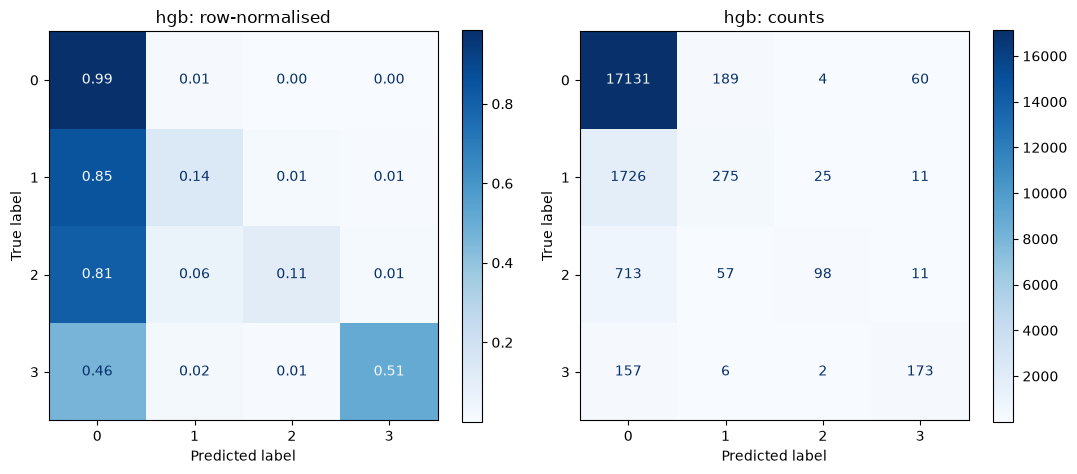

In [9]:
best_name = results_df.index[0]
print(f"Best model by {SORT_METRIC}: {MODEL_LABELS.get(best_name, best_name)}")
print("params:", best_params[best_name])
print()
print(classification_report(y_test, predictions[best_name], digits=3, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_name], labels=classes, normalize="true", cmap="Blues",
    values_format=".2f", ax=axes[0],
)
axes[0].set_title(f"{best_name}: row-normalised")
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_name], labels=classes, cmap="Blues",
    values_format="d", ax=axes[1],
)
axes[1].set_title(f"{best_name}: counts")
plt.tight_layout()
plt.show()